<a href="https://colab.research.google.com/github/ananthika123/AI-ML-ICT-Academy/blob/main/Case_Study_on_Pytorch_vs_Tensorflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Import libraries

In [97]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset

from tensorflow.keras import layers, Sequential
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

#Load the dataset

In [98]:
df=pd.read_csv("/content/adult_dataset.csv")
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


#Understand the data

In [99]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["income"].value_counts())

Shape: (48842, 15)

Columns:
Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

Data types:
age               float64
workclass          object
fnlwgt              int64
education          object
education-num       int64
marital-status     object
occupation         object
relationship       object
race               object
sex                object
capital-gain        int64
capital-loss        int64
hours-per-week    float64
native-country     object
income             object
dtype: object

Missing values:
age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per

#Separate features and target

In [100]:
# Separate features and target
X = df.drop(columns=["income"])

# Clean the target labels
y = df["income"].astype(str).str.strip().str.rstrip(".")

print(y.value_counts())

income
<=50K    37155
>50K     11687
Name: count, dtype: int64


#Encode the target

In [101]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(y)

print("Target classes:")
print(label_encoder.classes_)

Target classes:
['<=50K' '>50K']


#Identify numerical and categorical columns

In [102]:
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(include="object").columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

Numerical columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


#Train-test split

In [103]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (39073, 14)
X_test: (9769, 14)
y_train: (39073,)
y_test: (9769,)


#Handle missing values

In [104]:
# Numerical columns: median imputation
num_imputer = SimpleImputer(strategy="median")

X_train_num = num_imputer.fit_transform(
    X_train[numerical_cols]
)

X_test_num = num_imputer.transform(
    X_test[numerical_cols]
)

# Categorical columns: most frequent value
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_imputer.fit_transform(
    X_train[categorical_cols]
)

X_test_cat = cat_imputer.transform(
    X_test[categorical_cols]
)

#Encode categorical columns

In [105]:
encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train_cat)
X_test_cat = encoder.transform(X_test_cat)

print("Encoded categorical shape:", X_train_cat.shape)

Encoded categorical shape: (39073, 94)


#Scale numerical columns

In [106]:
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train_num)
X_test_num = scaler.transform(X_test_num)

#Combine numerical and categorical features

In [107]:
X_train_final = np.concatenate(
    [X_train_num, X_train_cat],
    axis=1
)

X_test_final = np.concatenate(
    [X_test_num, X_test_cat],
    axis=1
)

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (39073, 100)
Final testing shape: (9769, 100)


#Define the TensorFlow model

In [108]:
tf_model = Sequential([
    layers.Input(shape=(X_train_final.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

In [109]:
tf_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [110]:
tf_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [111]:
callbacks = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

#Train the model

In [112]:
history = tf_model.fit(
    X_train_final,
    y_train,
    batch_size=128,
    epochs=50,
    validation_split=0.2,
    callbacks=[callbacks],
    verbose=1
)

Epoch 1/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8201 - loss: 0.3901 - val_accuracy: 0.8518 - val_loss: 0.3247
Epoch 2/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8470 - loss: 0.3292 - val_accuracy: 0.8517 - val_loss: 0.3199
Epoch 3/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8503 - loss: 0.3222 - val_accuracy: 0.8499 - val_loss: 0.3188
Epoch 4/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8538 - loss: 0.3163 - val_accuracy: 0.8541 - val_loss: 0.3173
Epoch 5/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8554 - loss: 0.3143 - val_accuracy: 0.8528 - val_loss: 0.3169
Epoch 6/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8553 - loss: 0.3124 - val_accuracy: 0.8523 - val_loss: 0.3166
Epoch 7/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8568 - loss: 0.3105 - val_accuracy: 0.8531 - val_loss: 0.3163
Epoch 8/50
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8569 - loss: 0.3090 - val_accuracy: 0.

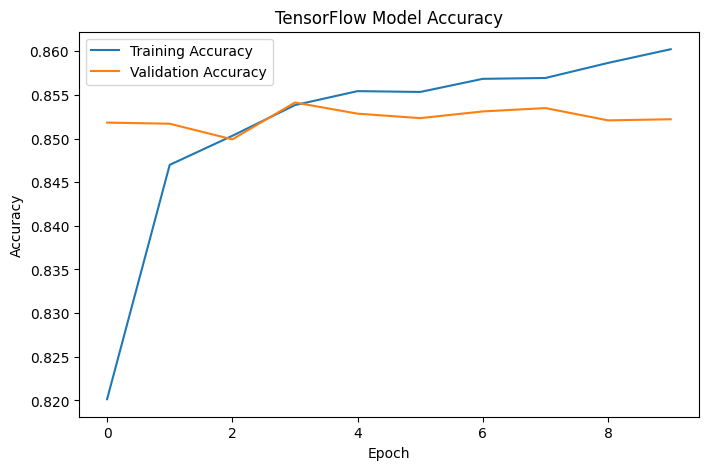

In [113]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("TensorFlow Model Accuracy")
plt.legend()
plt.show()

#Evaluate the model

In [114]:
test_loss, test_acc = tf_model.evaluate(
    X_test_final,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

Test Loss: 0.3102863132953644
Test Accuracy: 0.8566895127296448


In [115]:
y_prob_tf = tf_model.predict(X_test_final).ravel()

y_pred_tf = (y_prob_tf >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred_tf))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_tf,
        labels=[0, 1],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

306/306 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Accuracy: 0.8566895280990889

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7431
        >50K       0.75      0.61      0.67      2338

    accuracy                           0.86      9769
   macro avg       0.81      0.77      0.79      9769
weighted avg       0.85      0.86      0.85      9769



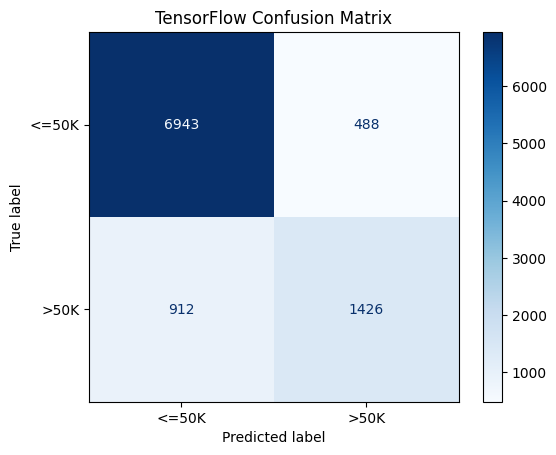

In [116]:
cm_tf = confusion_matrix(y_test, y_pred_tf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tf,
    display_labels=label_encoder.classes_
)

disp.plot(cmap=plt.cm.Blues)
plt.title("TensorFlow Confusion Matrix")
plt.show()

306/306 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


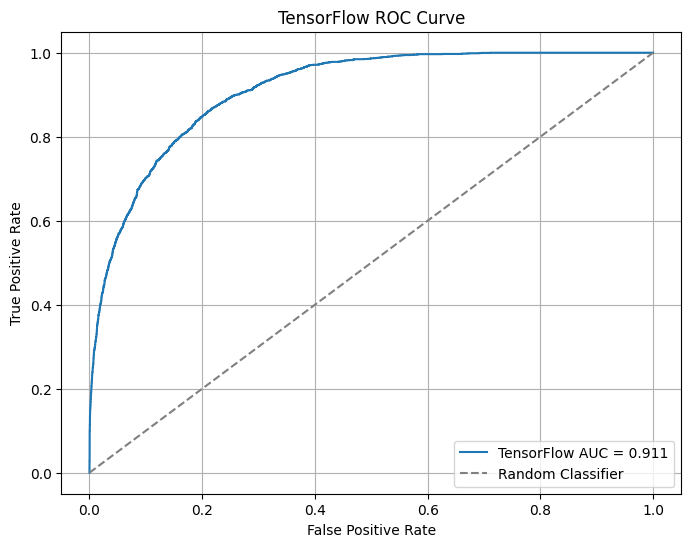

ROC AUC: 0.9114


In [117]:
fpr_tf, tpr_tf, thresholds_tf = roc_curve(
    y_test,
    y_prob_tf
)

auc_tf = roc_auc_score(y_test, y_prob_tf)

plt.figure(figsize=(7, 5))
plt.plot(fpr_tf, tpr_tf, label=f"TensorFlow AUC = {auc_tf:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("TensorFlow ROC Curve")
plt.legend()
plt.show()

print("ROC AUC:", auc_tf)

In [118]:
sample_index = 4

sample = X_test_final[sample_index:sample_index + 1]

sample_probability = tf_model.predict(sample, verbose=0)[0][0]

predicted_class = int(sample_probability >= 0.5)

predicted_income = label_encoder.inverse_transform(
    [predicted_class]
)[0]

print("Predicted income:", predicted_income)
print("Probability of >50K:", round(float(sample_probability), 4))
print("Actual income:", label_encoder.inverse_transform(
    [int(y_test[sample_index])]
)[0])

Predicted income: >50K
Probability of >50K: 0.5266
Actual income: >50K


##Part 2: PyTorch notebook

In [119]:
train_dataset = TensorDataset(
    torch.tensor(X_train_final, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.int64)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_final, dtype=torch.float32),
    torch.tensor(y_test, dtype=torch.int64)
)

In [120]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [121]:
class AdultIncomeModel(nn.Module):

    def __init__(
        self,
        input_features,
        hidden1_size,
        hidden2_size,
        num_classes,
        dropout_rate
    ):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_features, hidden1_size),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(hidden1_size, hidden2_size),
            nn.ReLU(),

            nn.Linear(hidden2_size, num_classes)
        )

    def forward(self, x):
        return self.network(x)

In [122]:
input_features = X_train_final.shape[1]
num_classes = len(np.unique(y_train))

print("Input features:", input_features)
print("Number of classes:", num_classes)

Input features: 100
Number of classes: 2


In [123]:
model = AdultIncomeModel(
    input_features=input_features,
    hidden1_size=64,
    hidden2_size=32,
    num_classes=num_classes,
    dropout_rate=0.3
)

print(model)

AdultIncomeModel(
  (network): Sequential(
    (0): Linear(in_features=100, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [124]:
loss_function = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

#Train the model

In [125]:
epochs = 50

for epoch in range(epochs):

    model.train()
    total_loss = 0

    for X_batch, y_batch in train_loader:

        prediction = model(X_batch)

        loss = loss_function(prediction, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Average Loss: {average_loss:.4f}"
        )

Epoch [10/50], Average Loss: 0.3004
Epoch [20/50], Average Loss: 0.2916
Epoch [30/50], Average Loss: 0.2842
Epoch [40/50], Average Loss: 0.2786
Epoch [50/50], Average Loss: 0.2766


#Evaluate the model

In [126]:
model.eval()

all_actual = []
all_predicted = []
all_probabilities = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        prediction = model(X_batch)

        probabilities = torch.softmax(prediction, dim=1)

        predicted_classes = torch.argmax(prediction, dim=1)

        all_actual.extend(y_batch.numpy())
        all_predicted.extend(predicted_classes.numpy())
        all_probabilities.extend(probabilities[:, 1].numpy())

print(
    "Accuracy:",
    accuracy_score(all_actual, all_predicted)
)

print("\nClassification Report:")

print(
    classification_report(
        all_actual,
        all_predicted,
        labels=[0, 1],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Accuracy: 0.8579179035725253

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      7431
        >50K       0.75      0.60      0.67      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.77      0.79      9769
weighted avg       0.85      0.86      0.85      9769



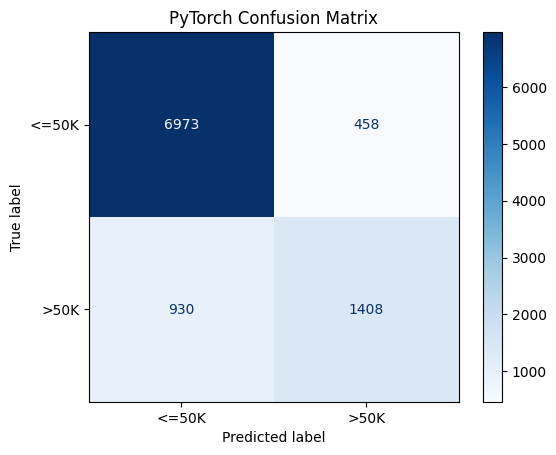

In [127]:
cm = confusion_matrix(
    all_actual,
    all_predicted,
    labels=[0, 1]
    )

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap=plt.cm.Blues)
plt.title("PyTorch Confusion Matrix")
plt.show()


Unique actual classes: [0 1]
Probability shape: (9769,)


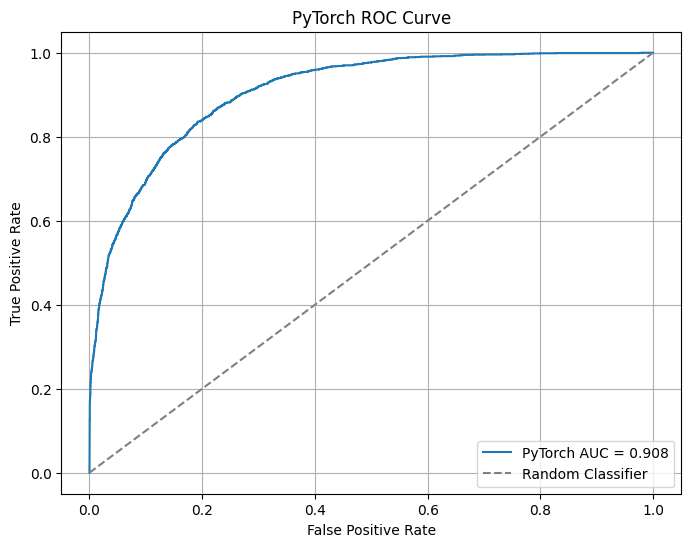

ROC AUC: 0.9077


In [129]:
# Evaluate the PyTorch model
model.eval()

all_actual = []
all_probabilities = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:

        outputs = model(X_batch)

        # Probability of class 1 (>50K)
        probs = torch.softmax(outputs, dim=1)

        all_probabilities.extend(probs[:, 1].cpu().numpy())
        all_actual.extend(y_batch.cpu().numpy())

all_actual = np.array(all_actual)
all_probabilities = np.array(all_probabilities)

# Check the classes
print("Unique actual classes:", np.unique(all_actual))
print("Probability shape:", all_probabilities.shape)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    all_actual,
    all_probabilities,
    pos_label=1
)

# Calculate AUC
auc_score = roc_auc_score(
    all_actual,
    all_probabilities
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"PyTorch AUC = {auc_score:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("PyTorch ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("ROC AUC:", round(auc_score, 4))

#PyTorch hyperparameter tuning using Optuna

In [130]:
!pip install optuna

In [131]:
import optuna

In [132]:
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train_final,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

train_data = TensorDataset(
    torch.tensor(X_train_split, dtype=torch.float32),
    torch.tensor(y_train_split, dtype=torch.int64)
)

val_data = TensorDataset(
    torch.tensor(X_val_split, dtype=torch.float32),
    torch.tensor(y_val_split, dtype=torch.int64)
)

input_features = X_train_final.shape[1]
num_classes = len(np.unique(y_train))

In [133]:
def objective(trial):

    lr = trial.suggest_categorical(
        "lr", [0.01, 0.001, 0.0001]
    )

    batch = trial.suggest_categorical(
        "batch_size", [32, 64, 128]
    )

    hidden1 = trial.suggest_categorical(
        "hidden1", [32, 64, 128]
    )

    hidden2 = trial.suggest_categorical(
        "hidden2", [16, 32, 64]
    )

    dropout_rate = trial.suggest_float(
        "dropout", 0.0, 0.3, step=0.1
    )

    train_loader = DataLoader(
        train_data,
        batch_size=batch,
        shuffle=True
    )

    val_loader = DataLoader(
        val_data,
        batch_size=batch,
        shuffle=False
    )

    model = AdultIncomeModel(
        input_features=input_features,
        hidden1_size=hidden1,
        hidden2_size=hidden2,
        num_classes=num_classes,
        dropout_rate=dropout_rate
    )

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    num_epochs = 10

    for epoch in range(num_epochs):

        model.train()

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            prediction = model(X_batch)

            loss = criterion(prediction, y_batch)

            loss.backward()
            optimizer.step()

    # Validation evaluation
    model.eval()

    val_actual = []
    val_predicted = []

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            prediction = model(X_batch)

            predicted_classes = torch.argmax(
                prediction,
                dim=1
            )

            val_actual.extend(y_batch.numpy())
            val_predicted.extend(predicted_classes.numpy())

    val_accuracy = accuracy_score(
        val_actual,
        val_predicted
    )

    return val_accuracy

In [134]:
study = optuna.create_study(
    direction="maximize"
)

study.optimize(
    objective,
    n_trials=10
)

print("Best parameters:")

for key, value in study.best_trial.params.items():
    print(f"{key}: {value}")

print(
    "\nBest validation accuracy:",
    round(study.best_value, 4)
)

[I 2026-10-21 18:34:39,069] A new study created in memory with name: no-name-eeb949bf-4f40-4616-b592-d04b7eb5599b
[I 2026-10-21 18:35:00,376] Trial 0 finished with value: 0.8586052463211772 and parameters: {'lr': 0.0001, 'batch_size': 128, 'hidden1': 128, 'hidden2': 64, 'dropout': 0.0}. Best is trial 0 with value: 0.8586052463211772.
[I 2026-10-21 18:35:10,500] Trial 1 finished with value: 0.855406269993602 and parameters: {'lr': 0.0001, 'batch_size': 128, 'hidden1': 64, 'hidden2': 16, 'dropout': 0.0}. Best is trial 0 with value: 0.8586052463211772.
[I 2026-10-21 18:35:25,606] Trial 2 finished with value: 0.8571976967370442 and parameters: {'lr': 0.01, 'batch_size': 32, 'hidden1': 32, 'hidden2': 32, 'dropout': 0.0}. Best is trial 0 with value: 0.8586052463211772.
[I 2026-10-21 18:35:32,247] Trial 3 finished with value: 0.854766474728087 and parameters: {'lr': 0.0001, 'batch_size': 128, 'hidden1': 64, 'hidden2': 16, 'dropout': 0.3}. Best is trial 0 with value: 0.8586052463211772.
[I 202

Best parameters:
lr: 0.001
batch_size: 32
hidden1: 128
hidden2: 64
dropout: 0.3

Best validation accuracy: 0.8615


In [135]:
best = study.best_params

full_train_loader = DataLoader(
    train_dataset,
    batch_size=best["batch_size"],
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=best["batch_size"],
    shuffle=False
)

final_model = AdultIncomeModel(
    input_features=input_features,
    hidden1_size=best["hidden1"],
    hidden2_size=best["hidden2"],
    num_classes=num_classes,
    dropout_rate=best["dropout"]
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    final_model.parameters(),
    lr=best["lr"]
)

epochs = 50

for epoch in range(epochs):

    final_model.train()

    for X_batch, y_batch in full_train_loader:

        optimizer.zero_grad()

        prediction = final_model(X_batch)

        loss = criterion(prediction, y_batch)

        loss.backward()
        optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch + 1}/{epochs}] completed")

Epoch [10/50] completed
Epoch [20/50] completed
Epoch [30/50] completed
Epoch [40/50] completed
Epoch [50/50] completed


In [136]:
final_model.eval()

test_actual = []
test_preds = []
test_probabilities = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        prediction = final_model(X_batch)

        probabilities = torch.softmax(
            prediction,
            dim=1
        )

        predicted_classes = torch.argmax(
            prediction,
            dim=1
        )

        test_actual.extend(y_batch.numpy())
        test_preds.extend(predicted_classes.numpy())
        test_probabilities.extend(probabilities[:, 1].numpy())

print("Final Test Accuracy:")
print(accuracy_score(test_actual, test_preds))

print("\nClassification Report:")

print(
    classification_report(
        test_actual,
        test_preds,
        labels=[0, 1],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

Final Test Accuracy:
0.8551540587572934

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.94      0.91      7431
        >50K       0.76      0.57      0.65      2338

    accuracy                           0.86      9769
   macro avg       0.82      0.76      0.78      9769
weighted avg       0.85      0.86      0.85      9769



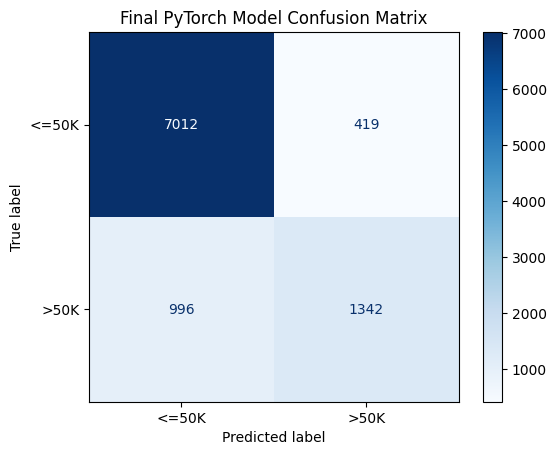

In [137]:
cm = confusion_matrix(
    test_actual,
    test_preds,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap=plt.cm.Blues)
plt.title("Final PyTorch Model Confusion Matrix")
plt.show()

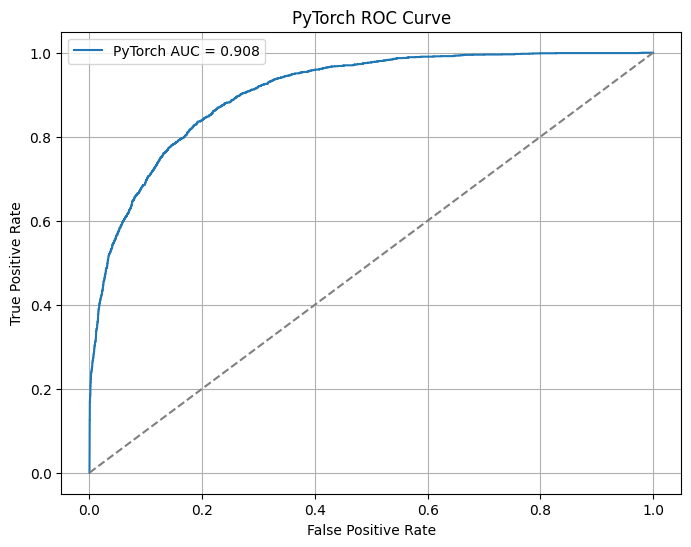

ROC AUC: 0.9077022435894115


In [138]:
# Binary ROC curve for PyTorch

fpr, tpr, thresholds = roc_curve(
    all_actual,
    all_probabilities,
    pos_label=1
)

auc_score = roc_auc_score(
    all_actual,
    all_probabilities
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"PyTorch AUC = {auc_score:.3f}"
)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("PyTorch ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("ROC AUC:", auc_score)